# Задача 4.9 — Деление отрезка на 3 части (остроугольный треугольник)

---

## 1. Условие

Отрезок $[0, 1]$ случайным образом делится на 3 части. Найти вероятность того, что из полученных отрезков можно сложить треугольник, и этот треугольник будет **остроугольным**. Построить график $p^{\wedge}(A)$ от $N = 150\,000$. Найдите аналитическое решение.

**Ответ:** $P(A) = 3\ln 2 - 2 \approx 0{,}0794$.

---

## 2. Теоретическая часть

### Модель

Пусть $x$ — первая точка (делит отрезок), $y \ge x$ — вторая. Тогда

$$
\Omega = \{(x, y): 0 \le x \le y \le 1\}, \quad \mu(\Omega) = \tfrac12.
$$

Длины частей: $a = x$, $b = y - x$, $c = 1 - y$.

### Условие треугольника

$$
a + b > c,\quad a + c > b,\quad b + c > a
\;\;\Longleftrightarrow\;\;
x < \tfrac12,\; y > \tfrac12,\; y - x < \tfrac12.
$$

Площадь области треугольника: $\mu = \tfrac18$, значит $P(\text{треугольник}) = \tfrac14$.

### Условие **остроугольности**

Для сторон $a, b, c$ нужно $a^2 + b^2 > c^2$ и циклические перестановки:

$$
x^2 + (y-x)^2 > (1-y)^2,\quad
x^2 + (1-y)^2 > (y-x)^2,\quad
(y-x)^2 + (1-y)^2 > x^2.
$$

Область остроугольных треугольников имеет площадь

$$
\mu(A) = \tfrac32\ln 2 - 1,
$$

откуда

$$
P(A) = \frac{\mu(A)}{\mu(\Omega)} = 3\ln 2 - 2 \approx 0{,}0794.
$$

---

## 3. Решение

P(остроугольный) = 3 ln 2 - 2 ≈ 0.0794415
P(треугольник) ≈ 0.250873  (теор. 0.25)
P(остроугольный) ≈ 0.079593


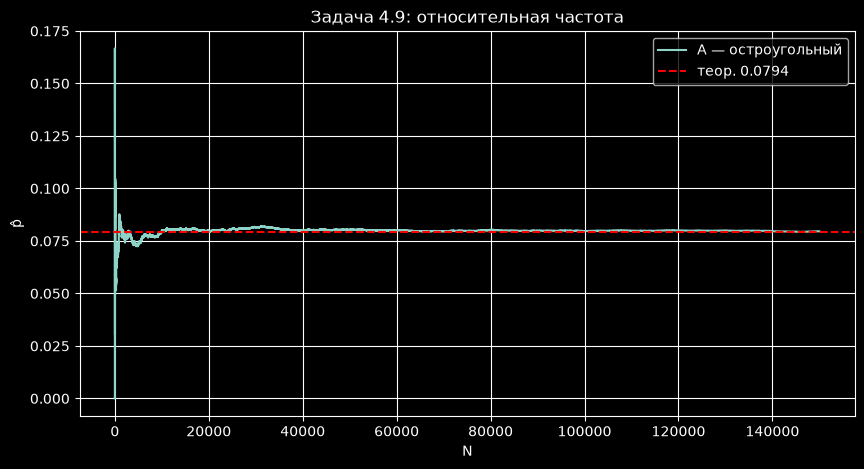

P(остроугольный) = 3 ln 2 - 2 ≈ 0.0794415
P(треугольник) ≈ 0.250873  (теор. 0.25)
P(остроугольный) ≈ 0.079593


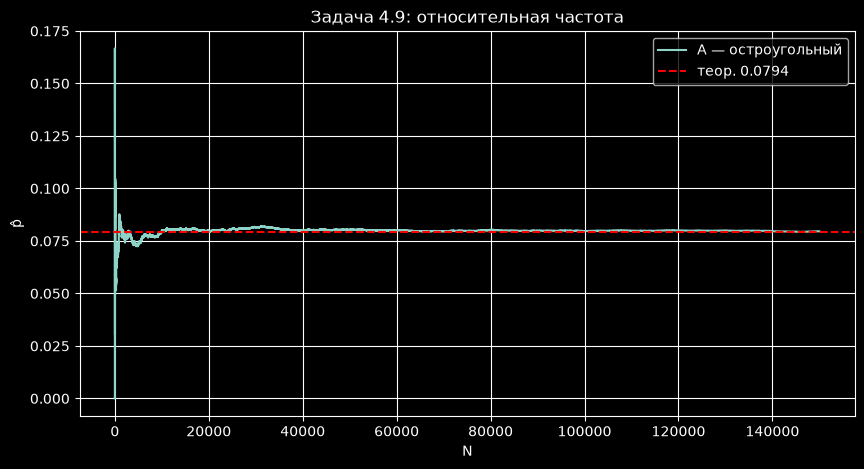

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Аналитика ----------
P_theor = 3*np.log(2) - 2
print(f"P(остроугольный) = 3 ln 2 - 2 ≈ {P_theor:.7f}")

# ---------- Моделирование ----------
N = 150_000
rng = np.random.default_rng(seed=8)
x = rng.uniform(0, 1, N)
y = rng.uniform(0, 1, N)
lo, hi = np.minimum(x, y), np.maximum(x, y)
a = lo
b = hi - lo
c = 1 - hi

# треугольник
tri = (a + b > c) & (a + c > b) & (b + c > a)
# остроугольный
acute = tri & (a**2 + b**2 > c**2) & (a**2 + c**2 > b**2) & (b**2 + c**2 > a**2)

print(f"P(треугольник) ≈ {tri.mean():.6f}  (теор. 0.25)")
print(f"P(остроугольный) ≈ {acute.mean():.6f}")

freq = np.cumsum(acute) / np.arange(1, N+1)
plt.figure(figsize=(10, 5))
plt.plot(freq, label="A — остроугольный")
plt.axhline(P_theor, color="r", ls="--", label=f"теор. {P_theor:.4f}")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.title("Задача 4.9: относительная частота")
plt.show()

import numpy as np
import matplotlib.pyplot as plt

# ---------- Аналитика ----------
P_theor = 3*np.log(2) - 2
print(f"P(остроугольный) = 3 ln 2 - 2 ≈ {P_theor:.7f}")

# ---------- Моделирование ----------
N = 150_000
rng = np.random.default_rng(seed=8)
x = rng.uniform(0, 1, N)
y = rng.uniform(0, 1, N)
lo, hi = np.minimum(x, y), np.maximum(x, y)
a = lo
b = hi - lo
c = 1 - hi

# треугольник
tri = (a + b > c) & (a + c > b) & (b + c > a)
# остроугольный
acute = tri & (a**2 + b**2 > c**2) & (a**2 + c**2 > b**2) & (b**2 + c**2 > a**2)

print(f"P(треугольник) ≈ {tri.mean():.6f}  (теор. 0.25)")
print(f"P(остроугольный) ≈ {acute.mean():.6f}")

freq = np.cumsum(acute) / np.arange(1, N+1)
plt.figure(figsize=(10, 5))
plt.plot(freq, label="A — остроугольный")
plt.axhline(P_theor, color="r", ls="--", label=f"теор. {P_theor:.4f}")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.title("Задача 4.9: относительная частота")
plt.show()